<a href="https://colab.research.google.com/github/amaldevk/automated-ticket-routing-sla-predictor/blob/main/Automated_Ticket_Routing_and_SLA_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras import layers, models
from xgboost import XGBClassifier

sns.set_theme(style='whitegrid')

In [55]:
df = pd.read_csv('/content/complaints-2026-10-05_16_49.csv')
print(f'Total Records Loaded: {df.shape[0]}')
print(f'Total Features: {df.shape[1]}')

Total Records Loaded: 52702
Total Features: 15


In [56]:
# Filter core product categories
target_products = [
    'Vehicle loan or lease',
    'Payday loan, title loan, personal loan, or advance loan',
    'Prepaid card',
    'Debt or credit management',
]
df_filtered = df[df['Product'].isin(target_products)].copy()

In [57]:
# Stratified downsampling to 25,000 records
target_n = 25000
counts = df_filtered['Product'].value_counts()
sample_sizes = (counts / len(df_filtered) * target_n).round().astype(int)
diff = target_n - sample_sizes.sum()
if diff != 0:
  sample_sizes.iloc[0] += diff

In [58]:
df_sampled = pd.concat([
    df_filtered[df_filtered['Product'] == prod].sample(n=size, random_state=42)
    for prod, size in sample_sizes.items()
])
print(f'Downsampled Dataset Shape: {df_sampled.shape}')

Downsampled Dataset Shape: (25000, 15)


/tmp/ipykernel_3131/1770423739.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


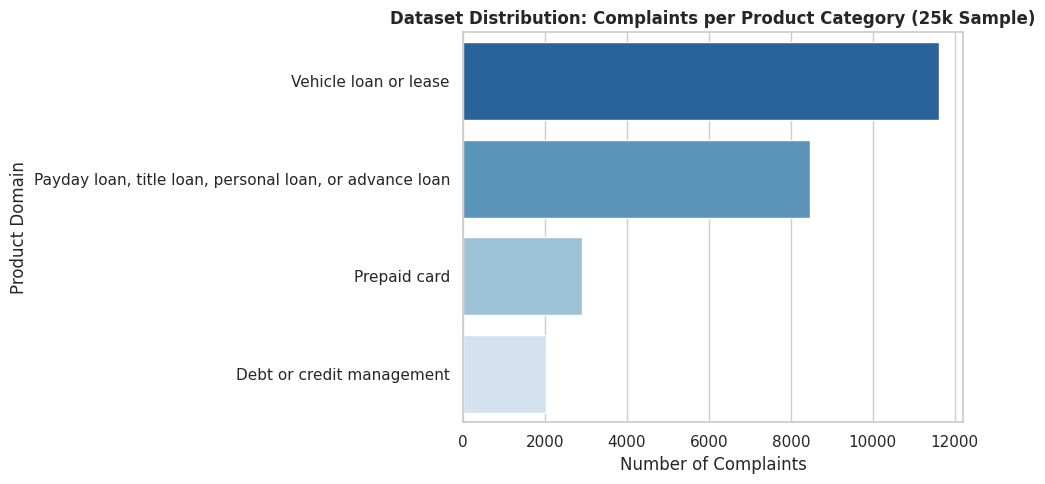

In [59]:
plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=df_sampled,
    y='Product',
    order=df_sampled['Product'].value_counts().index,
    palette='Blues_r',
)
plt.title(
    'Dataset Distribution: Complaints per Product Category (25k Sample)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Number of Complaints')
plt.ylabel('Product Domain')
plt.tight_layout()
plt.savefig('eda_product_distribution.png')
plt.show()

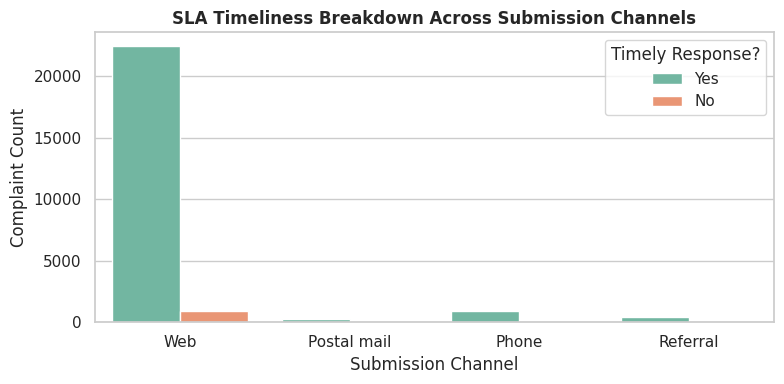

In [60]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=df_sampled,
    x='Submitted via',
    hue='Timely response?',
    palette='Set2',
)
plt.title(
    'SLA Timeliness Breakdown Across Submission Channels',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Submission Channel')
plt.ylabel('Complaint Count')
plt.legend(title='Timely Response?')
plt.tight_layout()
plt.savefig('eda_sla_by_channel.png')
plt.show()

In [61]:
features_to_check = [
    'Sub-issue',
    'Company',
    'Submitted via',
    'Timely response?',
]
df_sampled[features_to_check] = df_sampled[features_to_check].fillna('Unknown')

In [62]:
text_cols = ['Sub-issue', 'Company', 'Submitted via']
for col in text_cols:
  df_sampled[col] = df_sampled[col].astype(str).str.strip()

In [63]:
df_sampled['combined_text'] = (
    'Sub-issue: '
    + df_sampled['Sub-issue']
    + ' | Company: '
    + df_sampled['Company']
    + ' | Submitted via: '
    + df_sampled['Submitted via']
)

In [64]:
df_sampled['sla_target'] = df_sampled['Timely response?'].apply(
    lambda x: 1 if x == 'Yes' else 0
)

In [65]:
X = df_sampled['combined_text']
y_routing = df_sampled['Product']
y_sla = df_sampled['sla_target']

In [66]:
# Train / Validation / Test Stratified Split (80% / 10% / 10%)
X_train, X_temp, y_rout_train, y_rout_temp, y_sla_train, y_sla_temp = (
    train_test_split(
        X, y_routing, y_sla, test_size=0.20, random_state=42, stratify=y_routing
    )
)

In [67]:
X_val, X_test, y_rout_val, y_rout_test, y_sla_val, y_sla_test = (
    train_test_split(
        X_temp,
        y_rout_temp,
        y_sla_temp,
        test_size=0.50,
        random_state=42,
        stratify=y_rout_temp,
    )
)

In [68]:
print(f'Training Set Size: {X_train.shape[0]} rows')
print(f'Validation Set Size: {X_val.shape[0]} rows')
print(f'Test Set Size: {X_test.shape[0]} rows\n')

Training Set Size: 20000 rows
Validation Set Size: 2500 rows
Test Set Size: 2500 rows



In [69]:
# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = tfidf.fit_transform(X_train)
X_val_vec = tfidf.transform(X_val)
X_test_vec = tfidf.transform(X_test)
print(f'TF-IDF Training Feature Matrix Shape: {X_train_vec.shape}\n')

TF-IDF Training Feature Matrix Shape: (20000, 1353)



In [70]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_rout_train)
y_val_encoded = label_encoder.transform(y_rout_val)
y_test_encoded = label_encoder.transform(y_rout_test)

In [71]:
#Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_vec, y_train_encoded)
rf_preds = rf_model.predict(X_val_vec)
print(
    f'Random Forest Validation Accuracy:'
    f' {accuracy_score(y_val_encoded, rf_preds):.4f}'
)

Random Forest Validation Accuracy: 0.9464


In [72]:
#XGBoost Multiclass Classifier
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss',
)
xgb_model.fit(X_train_vec, y_train_encoded)
xgb_preds = xgb_model.predict(X_val_vec)
print(
    f'XGBoost Validation Accuracy: {accuracy_score(y_val_encoded, xgb_preds):.4f}'
)

XGBoost Validation Accuracy: 0.9376


In [73]:
#TensorFlow Deep Learning MLP
X_train_dense = X_train_vec.toarray()
X_val_dense = X_val_vec.toarray()

In [74]:
nn_model = models.Sequential([
    layers.Input(shape=(X_train_dense.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(label_encoder.classes_), activation='softmax'),
])

In [75]:
nn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

In [76]:
history = nn_model.fit(
    X_train_dense,
    y_train_encoded,
    validation_data=(X_val_dense, y_val_encoded),
    epochs=10,
    batch_size=64,
    verbose=0,
)

In [77]:
nn_loss, nn_acc = nn_model.evaluate(X_val_dense, y_val_encoded, verbose=0)
print(f'TensorFlow MLP Validation Accuracy: {nn_acc:.4f}\n')

TensorFlow MLP Validation Accuracy: 0.9512



In [78]:
#Predictive SLA Resolution Engine
sla_model = XGBClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42
)
sla_model.fit(X_train_vec, y_sla_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [79]:
sla_preds = sla_model.predict(X_val_vec)
print(
    f'SLA Risk Model Validation Accuracy:'
    f' {accuracy_score(y_sla_val, sla_preds):.4f}'
)

SLA Risk Model Validation Accuracy: 0.9672
